In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [3]:
image = cv2.imread("../pliki/dog.jpg")


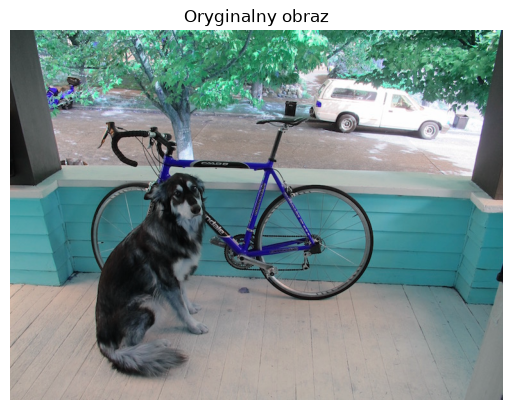

In [4]:
plt.imshow(image)
plt.title("Oryginalny obraz")
plt.axis("off")
plt.show()


### histogram jasności

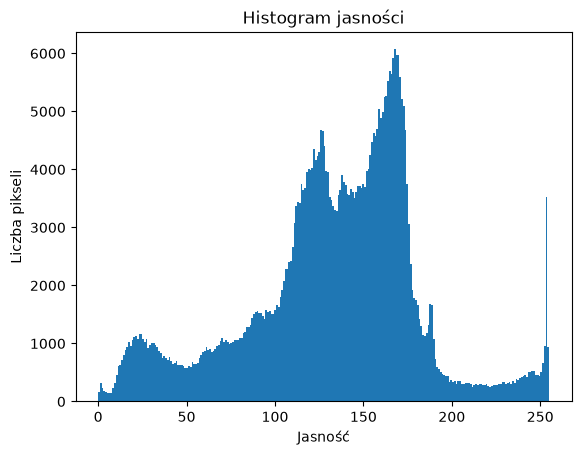

In [5]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.hist(gray.ravel(), bins=256)
plt.title("Histogram jasności")
plt.xlabel("Jasność")
plt.ylabel("Liczba pikseli")
plt.show()


### Zastosuj operatory Sobela, Prewitta i Robertsa do wykrycia krawędzi. Porównaj efekty uzyskane przez trzy operatory z oryginalnym obrazem.


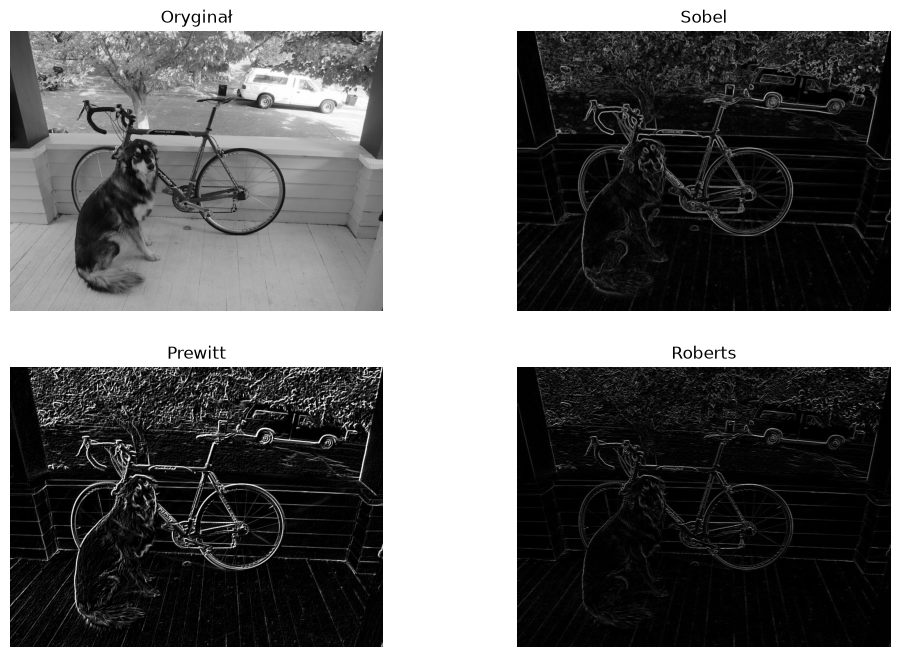

In [6]:
# Sobel
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1)
sobel = cv2.magnitude(sobelx, sobely)
# Prewitt
kernelx = np.array([[1,0,-1],
 [1,0,-1],
[1,0,-1]])
kernely = np.array([[1,1,1],
 [0,0,0],
[-1,-1,-1]])
prewittx = cv2.filter2D(gray, -1, kernelx)
prewitty = cv2.filter2D(gray, -1, kernely)
prewitt = cv2.add(prewittx, prewitty)
# Roberts
kernelx = np.array([[1,0],
 [0,-1]])
kernely = np.array([[0,1],
 [-1,0]])
robertsx = cv2.filter2D(gray, -1, kernelx)
robertsy = cv2.filter2D(gray, -1, kernely)
roberts = cv2.add(robertsx, robertsy)
# Wyświetlenie wyników
titles = ["Oryginał", "Sobel", "Prewitt", "Roberts"]
images = [gray, sobel, prewitt, roberts]
plt.figure(figsize=(12,8))
for i in range(4):
 plt.subplot(2, 2, i+1)
 plt.imshow(images[i], cmap="gray")
 plt.title(titles[i])
 plt.axis("off")
plt.show()